# Gold: all four variants, the paper's experiments, and a boosted ensemble

Trains and compares every model on `GC=F`, reproduces the paper's experiments
section for our own data, and exports everything the Streamlit app needs.

**The four models** (`roadmap.md`, "Variants reported by the paper"):

| Model | Backbone | Head |
| --- | --- | --- |
| LSTM-Real-NVP | LSTM | Real-NVP coupling flow |
| LSTM-MAF | LSTM | masked autoregressive flow |
| Transformer-MAF | attention | masked autoregressive flow |
| Vec-LSTM-ind-scaling | LSTM | diagonal Gaussian (the baseline) |

Vec-LSTM is the control: same backbone, same objective, but its head factorizes
over the three horizons. Whatever the flows win on `CRPS_sum` is therefore
attributable to modelling the joint cross-section, not to extra capacity.

**The target.** Each day is a 3-dimensional vector of trailing log returns,
`[return_1d, return_3d, return_7d]` with `return_h(t) = log(close(t)/close(t-h))`.
Every window ends on day `t`, so day `t` is always inside it: `return_3d(t)` is
`r(t-2)+r(t-1)+r(t)`, exactly the close-to-close return of a real 3-day candle
whose last daily candle is day `t`.

**What gets reported.** The flow samples all three dimensions freely, so its raw
`return_3d` for forecast day 1 ignores that two of those three days have already
traded. Every reported horizon is therefore *reconstructed*: the daily dimension
is compounded onto the last observed close, that path is spliced onto the observed
closes, and each horizon is read off the spliced series. Day 1 of the 3-day
horizon becomes the sampled daily return plus two known closes. The raw
dimensions are kept as a calibration diagnostic only.

**Outputs.** Paper Table 1 (`CRPS_sum`), Table 4 (`CRPS`) and Table 5 (`MSE`) for
gold, a leaderboard naming the best model, interval calibration, per-window and
per-seed metrics, the paper's fan charts and cross-covariance figures, and four
checkpoints plus boosting metadata for the app.

**Before you start:** run `python tools/make_colab_bundle.py` locally and upload
`gold_yahoo_colab.zip` to `/content/drive/MyDrive/fixed_notebooks/`. Then set
`Runtime > Change runtime type > T4 GPU` and run all cells.

In [1]:
#@title 1. Environment: unpack `project/` and `goldflow/` without editing them
%pip -q install yfinance pyyaml scikit-learn joblib

import shutil, sys, zipfile
from pathlib import Path

from google.colab import drive, files

drive.mount('/content/drive')

BUNDLE = Path('/content/drive/MyDrive/fixed_notebooks/gold_yahoo_colab.zip')
if not BUNDLE.exists():
    print('Upload gold_yahoo_colab.zip (build it with tools/make_colab_bundle.py)')
    BUNDLE = Path(next(iter(files.upload())))

WORK_ROOT = Path('/content/gold_yahoo_work')
if WORK_ROOT.exists():
    shutil.rmtree(WORK_ROOT)
WORK_ROOT.mkdir(parents=True)
with zipfile.ZipFile(BUNDLE) as archive:
    archive.extractall(WORK_ROOT)

for path in (WORK_ROOT, WORK_ROOT / 'project'):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import torch

from goldflow import pipeline, variants

print('bundle      :', BUNDLE)
print('project     :', (WORK_ROOT / 'project' / 'flowforecast').exists())
print('goldflow    :', (WORK_ROOT / 'goldflow' / 'pipeline.py').exists())
print('device      :', 'cuda' if torch.cuda.is_available() else 'cpu')
print('torch       :', torch.__version__)
print('variants    :', variants.variant_names())

Mounted at /content/drive
Upload gold_yahoo_colab.zip (build it with tools/make_colab_bundle.py)


Saving old_yahoo_colab.zip to old_yahoo_colab.zip
bundle      : old_yahoo_colab.zip
project     : True
goldflow    : True
device      : cuda
torch       : 2.11.0+cu128
variants    : ['lstm_realnvp', 'lstm_maf', 'transformer_maf', 'veclstm']


In [2]:
#@title 2. Experiment configuration
# SEEDS has three entries because Tables 4 and 5 report "the mean and standard
# errors obtained by re-running each method three times". Four variants times
# three seeds is twelve training runs; budget roughly an hour on a T4. Drop to
# SEEDS=(1,) for a quick pass -- the tables then show a single run and no stderr.
CONFIG = pipeline.PipelineConfig(
    ticker='GC=F',
    horizons=(1, 3, 7),
    context_length=30,
    prediction_length=10,
    lags=(1, 2),

    seeds=(1, 2, 3),
    epochs=40,
    batch_size=64,
    batches_per_epoch=100,

    # §5.2 protocol: rolling windows from the end of the training split, and
    # 100 samples for the empirical CDF.
    test_windows=20,
    validation_windows=20,
    evaluation_samples=100,
    validation_samples=100,

    # Stage 1 selection rounds, then the stride-1 blocks stage 2 is fitted and
    # gated on. Both live entirely inside the validation range.
    ensemble_rounds=24,
    boost_fit_windows=120,
    boost_gate_windows=40,
    boost_samples=30,
    enable_residual_booster=True,
    booster_min_gain_pct=1.0,

    work_dir=Path('/content/gold_yahoo_work/run'),
    export_dir=Path('/content/gold_yahoo_artifacts'),
)

runs = len(CONFIG.seeds) * len(variants.variant_names())
print(f'{runs} training runs: {len(variants.variant_names())} variants x {len(CONFIG.seeds)} seeds')
print(f'{CONFIG.epochs} epochs x {CONFIG.batches_per_epoch} batches of {CONFIG.batch_size}')
print(f'test: {CONFIG.test_windows} windows x {CONFIG.prediction_length} days, '
      f'{CONFIG.evaluation_samples} samples')
print(f'export -> {CONFIG.export_dir}')

12 training runs: 4 variants x 3 seeds
40 epochs x 100 batches of 64
test: 20 windows x 10 days, 100 samples
export -> /content/gold_yahoo_artifacts


In [3]:
#@title 3. Data: the target matrix, the real 3-day and 7-day candles, and the splits
import numpy as np
import pandas as pd

from goldflow import data

BUNDLE_DATA = pipeline.prepare(CONFIG)
prices, returns, splits = BUNDLE_DATA['prices'], BUNDLE_DATA['returns'], BUNDLE_DATA['splits']

print(f"prices        : {len(prices):,} daily candles "
      f"{prices.index.min().date()} -> {prices.index.max().date()}")
print(f"target rows   : {len(returns):,} aligned, D = {BUNDLE_DATA['num_series']}, "
      f"cond_size = {BUNDLE_DATA['cond_size']}")
print(f"train         : [0, {splits['train_end']})  -> {returns.index[splits['train_end'] - 1].date()}")
print(f"validation    : [{splits['train_end']}, {splits['validation_end']}) "
      f"-> {returns.index[splits['validation_end'] - 1].date()}")
print(f"test          : [{splits['validation_end']}, {splits['test_end']}) "
      f"-> {returns.index[splits['test_end'] - 1].date()}")

display((100 * returns.tail(5)).round(3).rename(columns=lambda c: c + ' (%)'))

# The h-day candle stamped on day t covers days t-h+1..t, so it contains day t.
# Its close-to-close return is log(close(t)/close(t-h)), which is precisely the
# return_{h}d column above. Verify that identity rather than trusting it.
for horizon in CONFIG.horizons:
    candles = data.aggregate_candles(prices, horizon)
    candle_return = np.log(candles['Close'] / prices['Close'].shift(horizon)).dropna()
    target = returns[f'return_{horizon}d']
    common = candle_return.index.intersection(target.index)
    gap = float((candle_return.loc[common] - target.loc[common]).abs().max())
    last = candles.iloc[-1]
    print(f"{horizon:>2}-day candle: window {last['WindowStart'].date()}..{candles.index[-1].date()} "
          f"O={last['Open']:.2f} H={last['High']:.2f} L={last['Low']:.2f} C={last['Close']:.2f} "
          f"| max |candle return - target| = {gap:.2e}")
    assert gap < 1e-5, f'the {horizon}-day candle disagrees with the training target'

prices        : 6,514 daily candles 2000-08-30 -> 2026-08-17
target rows   : 6,507 aligned, D = 3, cond_size = 10
train         : [0, 6107)  -> 2025-01-13
validation    : [6107, 6307) -> 2025-10-28
test          : [6307, 6507) -> 2026-08-17


,return_1d (%),return_3d (%),return_7d (%)
Date,,,
2026-08-11,0.485,3.270,7.924
2026-08-12,0.589,1.559,8.894
2026-08-13,-1.033,0.041,6.343
2026-08-14,0.384,-0.059,3.121
2026-08-17,1.630,0.982,4.841


 1-day candle: window 2026-08-17..2026-08-17 O=4440.00 H=4473.20 L=4422.30 C=4452.40 | max |candle return - target| = 3.58e-09
 3-day candle: window 2026-08-13..2026-08-17 O=4403.50 H=4473.20 L=4315.00 C=4452.40 | max |candle return - target| = 4.98e-09
 7-day candle: window 2026-08-07..2026-08-17 O=4277.00 H=4473.20 L=4274.00 C=4452.40 | max |candle return - target| = 7.12e-09


## Train, evaluate, and boost

One call runs the whole protocol, in this order:

1. **train** every variant for every seed through the project's unmodified `Trainer`
2. **evaluate** each on `test_windows` rolling windows (§5.2), scoring `CRPS_sum`,
   `CRPS`, `MSE` and `ND` both pooled and per return horizon
3. **boost stage 1** — forward stagewise CRPS selection, weights fitted on the
   **validation** windows only
4. **boost stage 2** — a gradient-boosted residual correction fitted on stride-1
   windows inside the validation range and gated on a **disjoint** tail of it;
   it only ships if it earns more than `booster_min_gain_pct`
5. **export** checkpoints, metadata and every table

Split discipline matters here: ensemble weights and the residual booster never
see the test range, so the test numbers reported for the boosted rows are as
honest as the ones for the individual models. Both boosted rows are reported
whether or not the gate accepted stage 2 — if the correction hurts, the table
says so.

In [4]:
#@title 4. Run everything (this is the long cell)
import time

started = time.time()
REPORT = pipeline.run(CONFIG)
print(f'\ntotal wall clock: {(time.time() - started) / 60:.1f} min')

[pipeline] 6,507 aligned target rows 2000-09-11 -> 2026-08-17
[pipeline] train [0, 6107) - validation [6107, 6307) - test [6307, 6507)
[pipeline] cond_size=10, device=cuda, seeds=[1, 2, 3]

[pipeline] === LSTM-Real-NVP, seed 1 ===
[trainer] OneCycleLR: base_lr=0.001, max_lr=0.003, 40 epochs x 100 batches
[trainer] epoch 1/40 - train_nll: 4.8093* - val_nll: 4.5792 (diagnostic)
[trainer] epoch 2/40 - train_nll: 3.8720* - val_nll: 3.6303 (diagnostic)
[trainer] epoch 3/40 - train_nll: 2.4555* - val_nll: 1.8085 (diagnostic)
[trainer] epoch 4/40 - train_nll: 1.6476* - val_nll: 1.8488 (diagnostic)
[trainer] epoch 5/40 - train_nll: 1.2216* - val_nll: 1.0681 (diagnostic)
[trainer] epoch 6/40 - train_nll: 1.0228* - val_nll: 1.0778 (diagnostic)
[trainer] epoch 7/40 - train_nll: 0.8389* - val_nll: 1.4758 (diagnostic)
[trainer] epoch 8/40 - train_nll: 0.5320* - val_nll: 0.2362 (diagnostic)
[trainer] epoch 9/40 - train_nll: 0.3318* - val_nll: 0.7699 (diagnostic)
[trainer] epoch 10/40 - train_nll: 0.

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.encoder = TransformerEncoder(


[trainer] epoch 1/40 - train_nll: 5.0850* - val_nll: 4.8945 (diagnostic)
[trainer] epoch 2/40 - train_nll: 4.0589* - val_nll: 3.3332 (diagnostic)
[trainer] epoch 3/40 - train_nll: 2.8711* - val_nll: 3.3125 (diagnostic)
[trainer] epoch 4/40 - train_nll: 2.4124* - val_nll: 2.3439 (diagnostic)
[trainer] epoch 5/40 - train_nll: 2.0310* - val_nll: 1.8199 (diagnostic)
[trainer] epoch 6/40 - train_nll: 1.7579* - val_nll: 1.8543 (diagnostic)
[trainer] epoch 7/40 - train_nll: 1.3490* - val_nll: 1.7948 (diagnostic)
[trainer] epoch 8/40 - train_nll: 1.1282* - val_nll: 1.7575 (diagnostic)
[trainer] epoch 9/40 - train_nll: 0.9309* - val_nll: 1.6803 (diagnostic)
[trainer] epoch 10/40 - train_nll: 0.8053* - val_crps_sum: 0.712099* - val_nll: 0.8546 (diagnostic)
[trainer] epoch 11/40 - train_nll: 0.6681* - val_nll: 3.2127 (diagnostic)
[trainer] epoch 12/40 - train_nll: 0.5464* - val_nll: 3.3573 (diagnostic)
[trainer] epoch 13/40 - train_nll: 0.4815* - val_nll: 1.5961 (diagnostic)
[trainer] epoch 14/40

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.encoder = TransformerEncoder(


[trainer] OneCycleLR: base_lr=0.001, max_lr=0.003, 40 epochs x 100 batches
[trainer] epoch 1/40 - train_nll: 5.0908* - val_nll: 5.0392 (diagnostic)
[trainer] epoch 2/40 - train_nll: 3.9441* - val_nll: 3.1045 (diagnostic)
[trainer] epoch 3/40 - train_nll: 2.6385* - val_nll: 2.6331 (diagnostic)
[trainer] epoch 4/40 - train_nll: 2.1852* - val_nll: 2.0449 (diagnostic)
[trainer] epoch 5/40 - train_nll: 1.7957* - val_nll: 1.6632 (diagnostic)
[trainer] epoch 6/40 - train_nll: 1.3579* - val_nll: 1.2674 (diagnostic)
[trainer] epoch 7/40 - train_nll: 1.0538* - val_nll: 2.0685 (diagnostic)
[trainer] epoch 8/40 - train_nll: 0.8791* - val_nll: 1.9402 (diagnostic)
[trainer] epoch 9/40 - train_nll: 0.7747* - val_nll: 1.7688 (diagnostic)
[trainer] epoch 10/40 - train_nll: 0.6114* - val_crps_sum: 0.669098* - val_nll: 2.9890 (diagnostic)
[trainer] epoch 11/40 - train_nll: 0.5243* - val_nll: 1.2869 (diagnostic)
[trainer] epoch 12/40 - train_nll: 0.4008* - val_nll: 5.1692 (diagnostic)
[trainer] epoch 13/4

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.encoder = TransformerEncoder(


[trainer] OneCycleLR: base_lr=0.001, max_lr=0.003, 40 epochs x 100 batches
[trainer] epoch 1/40 - train_nll: 5.0810* - val_nll: 5.1017 (diagnostic)
[trainer] epoch 2/40 - train_nll: 4.0309* - val_nll: 3.2763 (diagnostic)
[trainer] epoch 3/40 - train_nll: 2.6903* - val_nll: 2.2436 (diagnostic)
[trainer] epoch 4/40 - train_nll: 2.2048* - val_nll: 2.2744 (diagnostic)
[trainer] epoch 5/40 - train_nll: 1.9089* - val_nll: 1.9707 (diagnostic)
[trainer] epoch 6/40 - train_nll: 1.5396* - val_nll: 1.6941 (diagnostic)
[trainer] epoch 7/40 - train_nll: 1.3007* - val_nll: 1.7326 (diagnostic)
[trainer] epoch 8/40 - train_nll: 1.0237* - val_nll: 2.1615 (diagnostic)
[trainer] epoch 9/40 - train_nll: 0.8646* - val_nll: 1.6584 (diagnostic)
[trainer] epoch 10/40 - train_nll: 0.7088* - val_crps_sum: 0.672388* - val_nll: 2.4648 (diagnostic)
[trainer] epoch 11/40 - train_nll: 0.5380* - val_nll: 1.7450 (diagnostic)
[trainer] epoch 12/40 - train_nll: 0.4566* - val_nll: 1.3819 (diagnostic)
[trainer] epoch 13/4

In [5]:
#@title 5. Paper tables 1, 4 and 5 for gold
# Same orientation as the paper: columns are models, rows are the data set.
# Because gold is a single data set, CRPS and MSE are also broken out per return
# horizon -- the appendix averages those over D, so this is the same quantity at
# finer granularity. CRPS_sum is defined on the sum across D and stays one row.
for name, payload in REPORT['tables'].items():
    print(f"\n{payload['caption']}   [{name}]")
    display(payload['frame'])


Test set CRPS_sum (lower is better)   [table1_crps_sum]


,LSTM-Real-NVP,LSTM-MAF,Transformer-MAF,Vec-LSTM-ind-scaling,Boosted ensemble,Boosted + residual GB
Data set,,,,,,
Gold (GC=F),0.709±0.004,0.711±0.003,0.756±0.005,0.909±0.020,0.719±0.003,0.765±0.002



Test set CRPS (lower is better)   [table4_crps]


,LSTM-Real-NVP,LSTM-MAF,Transformer-MAF,Vec-LSTM-ind-scaling,Boosted ensemble,Boosted + residual GB
Data set,,,,,,
Gold (GC=F),0.693±0.003,0.693±0.001,0.749±0.003,0.873±0.014,0.702±0.002,0.742±0.001
Gold (GC=F) - 1-day return,0.789±0.002,0.784±0.004,0.791±0.002,0.881±0.015,0.783±0.004,0.847±0.002
Gold (GC=F) - 3-day return,0.741±0.001,0.739±0.001,0.768±0.001,0.922±0.016,0.746±0.000,0.790±0.001
Gold (GC=F) - 7-day return,0.628±0.005,0.629±0.004,0.722±0.006,0.840±0.016,0.645±0.006,0.672±0.002



Test set MSE (lower is better)   [table5_mse]


,LSTM-Real-NVP,LSTM-MAF,Transformer-MAF,Vec-LSTM-ind-scaling,Boosted ensemble,Boosted + residual GB
Data set,,,,,,
Gold (GC=F),9.0x10^-4,9.0x10^-4,1.0x10^-3,1.3x10^-3,9.3x10^-4,1.0x10^-3
Gold (GC=F) - 1-day return,3.5x10^-4,3.5x10^-4,3.6x10^-4,4.0x10^-4,3.5x10^-4,4.1x10^-4
Gold (GC=F) - 3-day return,8.6x10^-4,8.6x10^-4,9.2x10^-4,1.2x10^-3,8.8x10^-4,10.0x10^-4
Gold (GC=F) - 7-day return,1.5x10^-3,1.5x10^-3,1.9x10^-3,2.2x10^-3,1.6x10^-3,1.7x10^-3


In [6]:
#@title 6. Which model is best on gold, and is the difference real?
board = REPORT['leaderboard']
columns = ['Rank', 'Model', 'runs', 'crps_sum_mean', 'crps_sum_stderr',
           'crps_mean', 'crps_stderr', 'mse_mean', 'nd_mean', 'Gap vs best (%)']
display(board[columns].style.format({
    'crps_sum_mean': '{:.5f}', 'crps_sum_stderr': '{:.5f}',
    'crps_mean': '{:.5f}', 'crps_stderr': '{:.5f}',
    'mse_mean': '{:.3e}', 'nd_mean': '{:.5f}', 'Gap vs best (%)': '{:+.2f}',
}).background_gradient(subset=['crps_sum_mean'], cmap='RdYlGn_r'))

print(pipeline.format_winner(REPORT))

# A ranking is only meaningful if the gap clears the run-to-run noise. Compare
# every model against the winner using the pooled standard error of the two.
best = board.iloc[0]
print(f"\nAgainst {best['Model']} (CRPS_sum {best['crps_sum_mean']:.5f}):")
for _, row in board.iloc[1:].iterrows():
    difference = float(row['crps_sum_mean']) - float(best['crps_sum_mean'])
    pooled = float(np.hypot(row.get('crps_sum_stderr', 0.0) or 0.0,
                            best.get('crps_sum_stderr', 0.0) or 0.0))
    verdict = 'within noise' if pooled > 0 and difference < 2 * pooled else 'separated'
    margin = f'{difference / pooled:.1f} pooled stderr' if pooled > 0 else 'no stderr (single run)'
    print(f"  {row['Model']:<24} +{difference:.5f}  {margin:<28} {verdict}")

print('\nPer-seed detail:')
display(REPORT['per_seed'].pivot_table(
    index='Model', columns='seed', values='crps_sum').style.format('{:.5f}'))

,Rank,Model,runs,crps_sum_mean,crps_sum_stderr,crps_mean,crps_stderr,mse_mean,nd_mean,Gap vs best (%)
0,1,LSTM-Real-NVP,3,0.70878,0.00428,0.69342,0.00253,9.001e-04,0.87879,+0.00
1,2,LSTM-MAF,3,0.71086,0.00308,0.69271,0.00132,9.027e-04,0.87565,+0.29
2,3,Boosted ensemble,3,0.71942,0.00331,0.70215,0.00216,9.336e-04,0.88733,+1.50
3,4,Transformer-MAF,3,0.75644,0.00482,0.74926,0.00265,1.044e-03,0.94969,+6.72
4,5,Boosted + residual GB,3,0.76517,0.00168,0.74156,0.00129,1.040e-03,0.96346,+7.96
5,6,Vec-LSTM-ind-scaling,3,0.90914,0.01963,0.87337,0.01414,1.272e-03,1.08045,+28.27


Best on gold by CRPS_sum: LSTM-Real-NVP at 0.70878 ± 0.00428

Against LSTM-Real-NVP (CRPS_sum 0.70878):
  LSTM-MAF                 +0.00208  0.4 pooled stderr            within noise
  Boosted ensemble         +0.01064  2.0 pooled stderr            within noise
  Transformer-MAF          +0.04766  7.4 pooled stderr            separated
  Boosted + residual GB    +0.05639  12.3 pooled stderr           separated
  Vec-LSTM-ind-scaling     +0.20036  10.0 pooled stderr           separated

Per-seed detail:


seed,1,2,3
Model,,,
Boosted + residual GB,0.76327,0.76928,0.76296
Boosted ensemble,0.71632,0.72745,0.71448
LSTM-MAF,0.70836,0.71828,0.70595
LSTM-Real-NVP,0.70802,0.71821,0.70011
Transformer-MAF,0.76159,0.76307,0.74467
Vec-LSTM-ind-scaling,0.86876,0.90672,0.95193


In [7]:
#@title 7. Boosting detail and interval calibration
import json

metadata = json.loads((CONFIG.export_dir / 'gold_yahoo_metadata.json').read_text())
boost = metadata['boosting']

print('Stage 1 - forward stagewise CRPS mixture weights (fitted on validation):')
for key, weight in sorted(boost['weights'].items(), key=lambda kv: -kv[1]):
    label = REPORT['labels'].get(key, key)
    bar = '#' * int(round(40 * weight))
    print(f"  {label:<24} {100 * weight:5.1f}%  {bar}")
print(f"  pool size {boost['pool_size']} over {len(boost['rounds'])} rounds")

print(f"\nStage 2 - gradient-boosted residual correction: "
      f"{'ENABLED' if boost['booster_enabled'] else 'REJECTED'}")
gate = boost['booster_metrics']
if gate:
    print(f"  gate CRPS_sum {gate['crps_sum_before']:.5f} -> {gate['crps_sum_after']:.5f} "
          f"({gate['gain_pct']:+.2f}%, needs > {gate['min_gain_pct']:.1f}%)")
    print(f"  fitted on {int(gate.get('fit_rows', 0)):,} residual rows")
if not boost['booster_enabled']:
    print('  The correction did not clear the threshold on held-out windows, so it is')
    print('  not exported and the app serves the stage 1 mixture only. Its test row is')
    print('  still in the tables above so the result is visible rather than hidden.')

print('\nInterval calibration on the test windows (nominal 80% and 95%):')
display(REPORT['coverage'].style.format({
    '80% coverage': '{:.1f}', '80% width': '{:.4f}',
    '95% coverage': '{:.1f}', '95% width': '{:.4f}',
    'Median bias': '{:+.5f}', 'Direction hit rate': '{:.1f}',
}).background_gradient(subset=['80% coverage', '95% coverage'], cmap='RdYlGn'))
print('Coverage far below the nominal level means the bands are too tight to size a')
print('position with, however good the CRPS looks.')

print('\nPer-horizon metrics, every model and seed:')
display(REPORT['per_horizon'].pivot_table(
    index=['Model', 'Return horizon'], values=['crps', 'mse', 'nd']
).style.format({'crps': '{:.5f}', 'mse': '{:.3e}', 'nd': '{:.5f}'}))

Stage 1 - forward stagewise CRPS mixture weights (fitted on validation):
  LSTM-MAF                  75.0%  ##############################
  Transformer-MAF           25.0%  ##########
  LSTM-Real-NVP              0.0%  
  Vec-LSTM-ind-scaling       0.0%  
  pool size 24 over 24 rounds

Stage 2 - gradient-boosted residual correction: REJECTED
  gate CRPS_sum 0.60999 -> 0.92308 (-51.33%, needs > 1.0%)
  fitted on 3,600 residual rows
  The correction did not clear the threshold on held-out windows, so it is
  not exported and the app serves the stage 1 mixture only. Its test row is
  still in the tables above so the result is visible rather than hidden.

Interval calibration on the test windows (nominal 80% and 95%):


,Model,Return horizon,80% coverage,80% width,95% coverage,95% width,Median bias,Direction hit rate
0,LSTM-Real-NVP,1-day,77.5,0.0415,92.0,0.0697,+0.00054,53.0
1,LSTM-Real-NVP,3-day,75.0,0.0676,89.5,0.1069,+0.00218,58.5
2,LSTM-Real-NVP,7-day,75.0,0.0896,88.5,0.1385,+0.00615,70.0
3,LSTM-MAF,1-day,79.5,0.0418,91.5,0.0694,+0.00058,51.0
4,LSTM-MAF,3-day,75.0,0.0685,88.0,0.1076,+0.00202,58.0
5,LSTM-MAF,7-day,75.5,0.0915,88.0,0.1385,+0.00592,67.5
6,Transformer-MAF,1-day,83.5,0.0463,93.5,0.0778,+0.00061,51.0
7,Transformer-MAF,3-day,77.5,0.0792,90.5,0.1287,+0.00355,56.5
8,Transformer-MAF,7-day,79.5,0.1196,91.5,0.1914,+0.00606,58.0
9,Vec-LSTM-ind-scaling,1-day,58.0,0.0308,74.5,0.0476,+0.00052,56.0


Coverage far below the nominal level means the bands are too tight to size a
position with, however good the CRPS looks.

Per-horizon metrics, every model and seed:


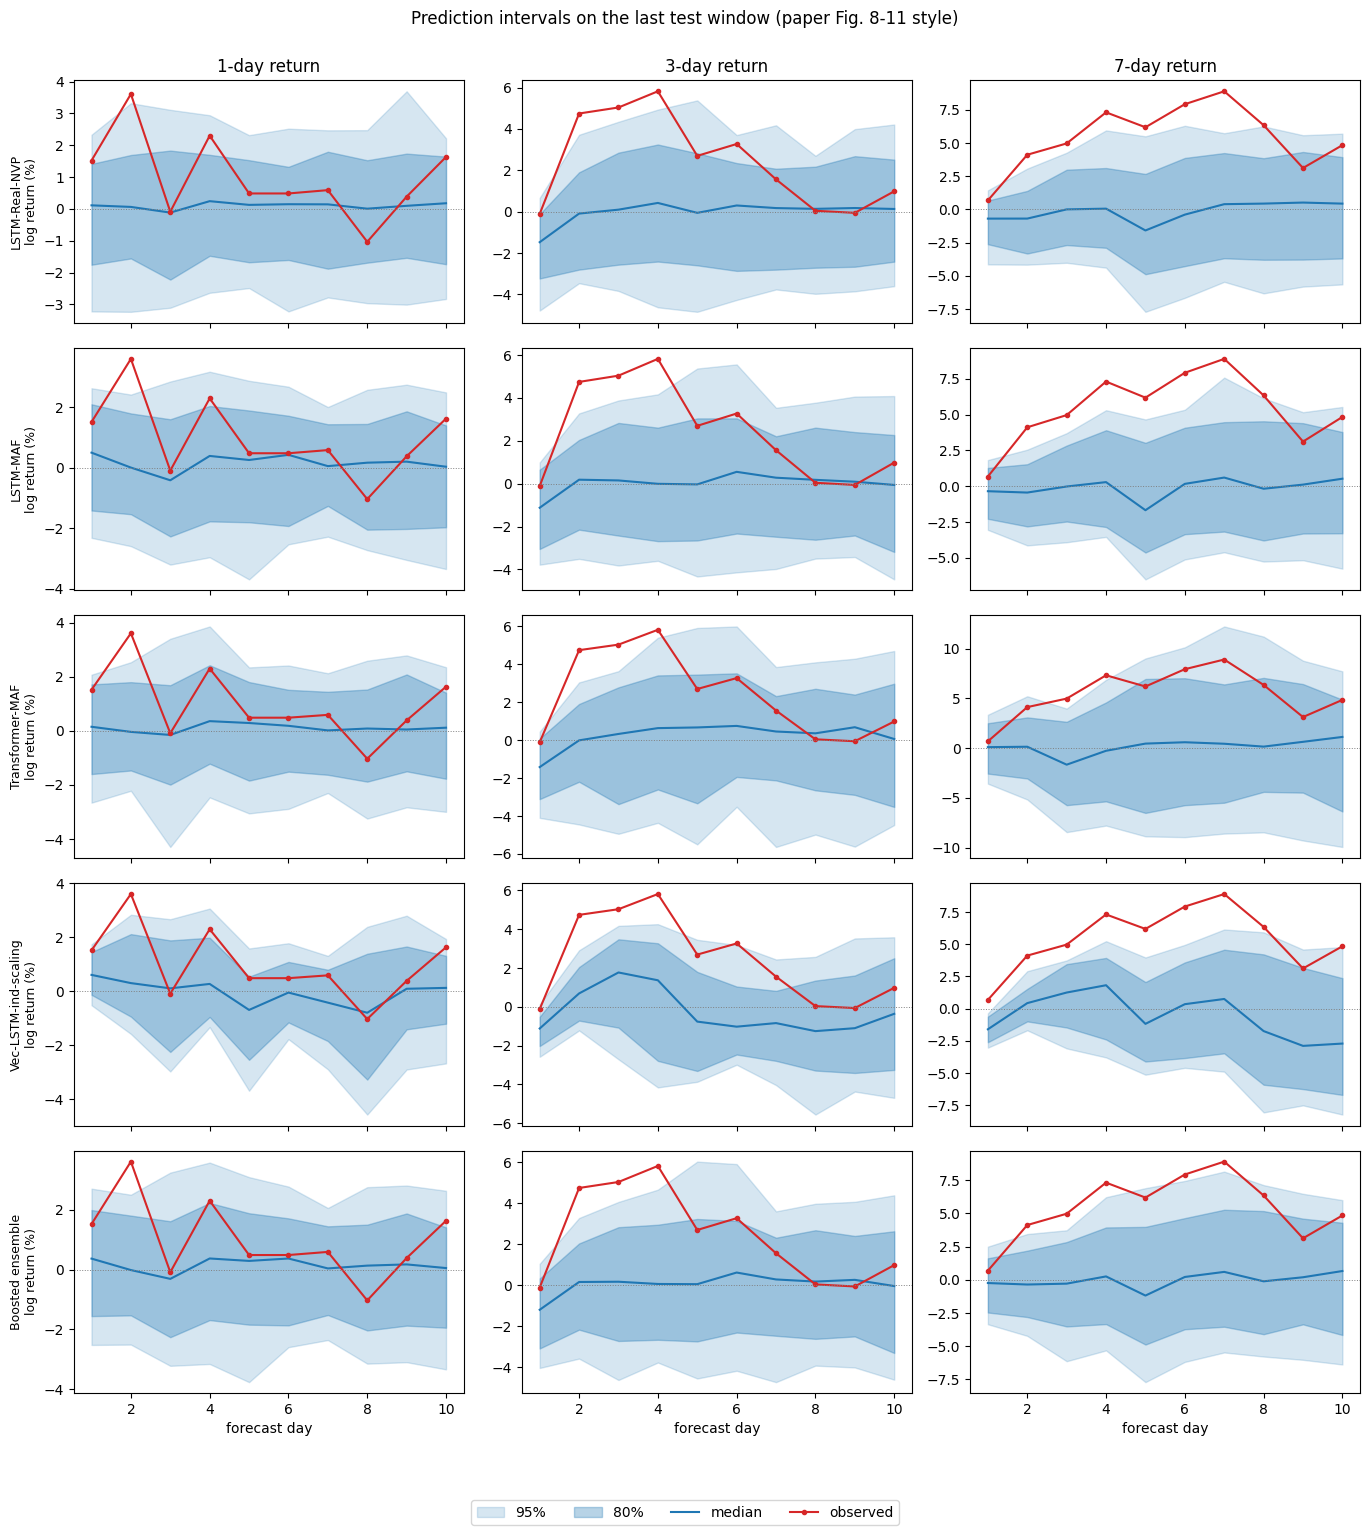

[plots] wrote /content/gold_yahoo_artifacts/figures/cross_covariance_lstm_realnvp.png
[plots] wrote /content/gold_yahoo_artifacts/figures/cross_covariance_lstm_maf.png
[plots] wrote /content/gold_yahoo_artifacts/figures/cross_covariance_transformer_maf.png
[plots] wrote /content/gold_yahoo_artifacts/figures/cross_covariance_veclstm.png
[plots] wrote /content/gold_yahoo_artifacts/figures/cross_covariance_boosted.png


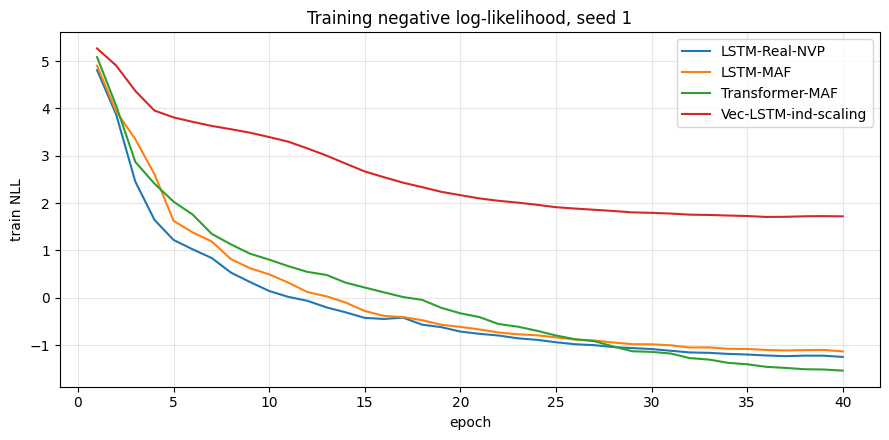

figures: ['cross_covariance_boosted.png', 'cross_covariance_lstm_maf.png', 'cross_covariance_lstm_realnvp.png', 'cross_covariance_transformer_maf.png', 'cross_covariance_veclstm.png', 'learning_curves.png', 'prediction_intervals.png']


In [8]:
#@title 8. Paper figures: prediction intervals (Fig. 8-11) and cross-covariance (Fig. 5)
import matplotlib.pyplot as plt

from flowforecast.data.toy_pipes import empirical_cross_covariance
from flowforecast.evaluation.plots import plot_covariance_comparison

FIGURES = CONFIG.export_dir / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

test_blocks = REPORT['export']['test']
mixture = REPORT['export']['mixture']
labels = REPORT['labels']
series_labels = [f'{h}-day return' for h in CONFIG.horizons]
models_shown = list(test_blocks) + ['boosted']

# Figures 8-11: observations against the predicted interval on the last test
# window, one column per return horizon and one row per model.
fig, axes = plt.subplots(len(models_shown), len(CONFIG.horizons),
                         figsize=(4.6 * len(CONFIG.horizons), 3.1 * len(models_shown)),
                         sharex=True, squeeze=False)
targets = next(iter(test_blocks.values()))['targets']
for row, key in enumerate(models_shown):
    block = mixture if key == 'boosted' else test_blocks[key]['samples']
    samples = block[-1].numpy()
    target = targets[-1].numpy()
    for column, horizon in enumerate(CONFIG.horizons):
        axis = axes[row][column]
        draws = 100 * samples[:, column, :]
        steps = np.arange(1, draws.shape[1] + 1)
        axis.fill_between(steps, np.quantile(draws, 0.025, axis=0),
                          np.quantile(draws, 0.975, axis=0),
                          color='tab:blue', alpha=0.18, label='95%')
        axis.fill_between(steps, np.quantile(draws, 0.10, axis=0),
                          np.quantile(draws, 0.90, axis=0),
                          color='tab:blue', alpha=0.32, label='80%')
        axis.plot(steps, np.median(draws, axis=0), color='tab:blue', label='median')
        axis.plot(steps, 100 * target[column], color='tab:red', marker='o',
                  markersize=3, label='observed')
        axis.axhline(0, color='grey', linewidth=0.7, linestyle=':')
        if row == 0:
            axis.set_title(f'{horizon}-day return')
        if column == 0:
            axis.set_ylabel(f'{labels[key]}\nlog return (%)', fontsize=9)
        if row == len(models_shown) - 1:
            axis.set_xlabel('forecast day')
handles, legend_labels = axes[0][0].get_legend_handles_labels()
fig.suptitle('Prediction intervals on the last test window (paper Fig. 8-11 style)')
fig.legend(handles, legend_labels, loc='lower center', ncol=4)
fig.tight_layout(rect=(0, 0.05, 1, 0.98))
fig.savefig(FIGURES / 'prediction_intervals.png', dpi=150)
plt.show()

# Figure 5: cross-covariance between consecutive days. At D = 3 the matrix is
# small enough to read entry by entry, so the off-diagonals show directly whether
# a model captured the lead-lag structure between the 1, 3 and 7-day horizons.
data_cov = torch.stack([empirical_cross_covariance(targets[w])
                        for w in range(targets.shape[0])]).mean(dim=0)
for key in models_shown:
    block = mixture if key == 'boosted' else test_blocks[key]['samples']
    fitted = torch.stack([
        torch.stack([empirical_cross_covariance(block[w, s])
                     for s in range(block.shape[1])]).mean(dim=0)
        for w in range(block.shape[0])
    ]).mean(dim=0)
    plot_covariance_comparison(
        data_cov, fitted, labels=series_labels, show_diff=True,
        titles=('Data', 'Samples'),
        suptitle=f'Cross-covariance x_t vs x_(t+1) - {labels[key]} (Fig. 5 style)',
        save_path=str(FIGURES / f'cross_covariance_{key}.png'))

# Learning curves for the exported seed.
fig, axis = plt.subplots(figsize=(9, 4.5))
for key, history in REPORT['learning_curves'].items():
    curve = history.get('train_nll') or []
    if curve:
        axis.plot(range(1, len(curve) + 1), curve, label=labels.get(key, key))
axis.set_xlabel('epoch')
axis.set_ylabel('train NLL')
axis.set_title(f'Training negative log-likelihood, seed {CONFIG.export_seed}')
axis.grid(alpha=0.3)
axis.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'learning_curves.png', dpi=150)
plt.show()

print('figures:', sorted(p.name for p in FIGURES.glob('*.png')))

In [9]:
#@title 9. The horizon fix, demonstrated on a live forecast
# This is what the app reports. For each model the daily dimension is compounded
# onto the last observed close, that path is spliced onto the observed closes,
# and every horizon is read off the spliced series. The assertions below are the
# actual guarantees: reported horizons are mutually consistent, and the window of
# each h-day return ends on -- and therefore contains -- its own forecast day.
from goldflow import forecast

live = {}
for key, model in REPORT['models'].items():
    live[key] = forecast.forecast_prices(
        model, key, REPORT['labels'][key], prices, returns, CONFIG.horizons,
        list(CONFIG.lags), CONFIG.context_length, CONFIG.prediction_length,
        num_samples=500, device=CONFIG.device, seed=20260817,
    )

close = prices['Close'].to_numpy()
for key, result in live.items():
    daily = result.horizon_returns[1]
    for horizon in CONFIG.horizons:
        derived = result.horizon_returns[horizon]
        # Fully-forecast day: the h-day return must equal the sum of h daily returns.
        gap = float(np.abs(daily[:, :horizon].sum(axis=1) - derived[:, horizon - 1]).max())
        assert gap < 1e-10, f'{key} horizon {horizon} is not self-consistent ({gap})'
        # Day 1: the h-day return must be the first sampled daily return plus the
        # h-1 daily returns that have already traded.
        observed = float(np.log(close[-1] / close[-horizon])) if horizon > 1 else 0.0
        gap = float(np.abs(observed + daily[:, 0] - derived[:, 0]).max())
        assert gap < 1e-10, f'{key} horizon {horizon} day 1 splice is wrong ({gap})'
print('reported horizons are self-consistent and include their own forecast day')

reference = next(iter(live.values()))
print(f'\nCalibration gap for {reference.model_name}: '
      f'raw flow dimensions against the reconstruction')
gaps = forecast.consistency_report(reference)
display(gaps[gaps['Return horizon'] == '3-day'].head(4).style.format({
    'Observed share of window': '{:.2f}', 'Model median (%)': '{:+.3f}',
    'Reconstructed median (%)': '{:+.3f}', 'Median gap (pp)': '{:+.3f}',
    'Model sigma (%)': '{:.3f}', 'Reconstructed sigma (%)': '{:.3f}',
}).hide(axis='index'))
print('On forecast day 1 two thirds of the 3-day window has already traded, so the')
print('raw flow sigma should be visibly wider than the reconstructed one. That gap')
print('is exactly the error the old export made by reporting the raw dimension.')

print('\nDay-10 price and next-day direction, all models:')
rows = []
for result in live.values():
    quantiles = np.quantile(result.price_paths[:, -1], [0.10, 0.50, 0.90])
    draws = result.horizon_returns[1][:, 0]
    rows.append({
        'Model': result.model_name,
        'Day 10 80% low': quantiles[0], 'Day 10 median': quantiles[1],
        'Day 10 80% high': quantiles[2],
        'P(next day up) %': 100 * float((draws > 0).mean()),
    })
display(pd.DataFrame(rows).style.format({
    'Day 10 80% low': '${:,.2f}', 'Day 10 median': '${:,.2f}',
    'Day 10 80% high': '${:,.2f}', 'P(next day up) %': '{:.1f}',
}).hide(axis='index'))

reported horizons are self-consistent and include their own forecast day

Calibration gap for LSTM-Real-NVP: raw flow dimensions against the reconstruction


Forecast day,Return horizon,Observed share of window,Model median (%),Reconstructed median (%),Median gap (pp),Model sigma (%),Reconstructed sigma (%)
1,3-day,0.67,+1.597,+1.640,+0.043,1.493,1.563
2,3-day,0.33,+1.343,+1.416,+0.073,1.933,1.998
3,3-day,0.00,-0.002,-0.026,-0.025,2.196,2.280
4,3-day,0.00,+0.511,+0.534,+0.023,2.003,2.092


On forecast day 1 two thirds of the 3-day window has already traded, so the
raw flow sigma should be visibly wider than the reconstructed one. That gap
is exactly the error the old export made by reporting the raw dimension.

Day-10 price and next-day direction, all models:


Model,Day 10 80% low,Day 10 median,Day 10 80% high,P(next day up) %
LSTM-Real-NVP,"$4,198.71","$4,478.51","$4,711.77",38.2
LSTM-MAF,"$4,190.90","$4,451.83","$4,675.01",38.4
Transformer-MAF,"$4,160.54","$4,488.81","$4,761.02",50.6
Vec-LSTM-ind-scaling,"$4,329.49","$4,492.85","$4,692.17",99.0


In [10]:
#@title 10. Copy the artifacts to Drive and download them
target = pipeline.copy_to_drive(CONFIG)

for path in sorted(CONFIG.export_dir.rglob('*')):
    if path.is_file():
        print(f"  {path.relative_to(CONFIG.export_dir)}  "
              f"({path.stat().st_size / 1024:.0f} KB)")

archive = shutil.make_archive('/content/gold_yahoo_artifacts', 'zip',
                              str(CONFIG.export_dir))
print(f'\narchive: {archive}')
files.download(archive)

print('\nNext: unzip this over gold-yahoo/artifacts/ so it contains')
print('  gold_yahoo_metadata.json')
print('  models/{lstm_realnvp,lstm_maf,transformer_maf,veclstm}.pt')
print('  experiments/*.csv  and  figures/*.png')
print('  gold_yahoo_booster.joblib   (only when stage 2 passed its gate)')
print('Then run: streamlit run app.py')

[pipeline] copied artifacts to /content/drive/MyDrive/gold_yahoo_artifacts
  experiments/coverage.csv  (2 KB)
  experiments/leaderboard.csv  (1 KB)
  experiments/learning_curves.json  (9 KB)
  experiments/per_horizon.csv  (6 KB)
  experiments/per_seed.csv  (2 KB)
  experiments/per_window_metrics.csv  (39 KB)
  experiments/table1_crps_sum.csv  (0 KB)
  experiments/table4_crps.csv  (1 KB)
  experiments/table5_mse.csv  (0 KB)
  figures/cross_covariance_boosted.png  (66 KB)
  figures/cross_covariance_lstm_maf.png  (78 KB)
  figures/cross_covariance_lstm_realnvp.png  (77 KB)
  figures/cross_covariance_transformer_maf.png  (74 KB)
  figures/cross_covariance_veclstm.png  (72 KB)
  figures/learning_curves.png  (88 KB)
  figures/prediction_intervals.png  (684 KB)
  gold_yahoo_metadata.json  (12 KB)
  models/lstm_maf.pt  (3279 KB)
  models/lstm_realnvp.pt  (5288 KB)
  models/transformer_maf.pt  (4183 KB)
  models/veclstm.pt  (287 KB)

archive: /content/gold_yahoo_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Next: unzip this over gold-yahoo/artifacts/ so it contains
  gold_yahoo_metadata.json
  models/{lstm_realnvp,lstm_maf,transformer_maf,veclstm}.pt
  experiments/*.csv  and  figures/*.png
  gold_yahoo_booster.joblib   (only when stage 2 passed its gate)
Then run: streamlit run app.py
